<a href="https://colab.research.google.com/github/Ming25w/RL/blob/main/comp64101_coursework_2026_2027.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment Brief: Probabilistic Programming

## Deadline: October 28, 2026, 14:00 GMT

## Number of marks available: 10

In this coursework you will use probabilistic programming to perform Bayesian inference in different models.

### Please READ the whole assignment first, before starting to work on it.

### How and what to submit

A. A **Jupyter Notebook** with the code in all the cells executed and outputs displayed.

B. Name your Notebook **COM64101_CW1_XXXXXX.ipynb** where XXXXXX is your username such as such as abc18de. Example: `COM64101_CW1_abc18de.ipynb`

C. Upload the Jupyter Notebook in B to Canvas under the submission area before the deadline.

D. **NO DATA UPLOAD**: Please do not upload the data files used in this Notebook, if any. We have a copy already.


### Assessment Criteria

* Being able to compute the posterior distribution in Bayesian logistic regression using a probabilistic program.

### Code quality and use of Python libraries
When writing your code, you will find out that there are operations that are repeated at least twice. If your code is unreadable, we may not award marks for that section. Make sure to check the following:

* Did you include Python functions to solve the question and avoid repeating code?
* Did you comment your code to make it readable to others?

### Late submissions

We follow Department's guidelines about late submissions, i.e., a deduction of 10% of the mark each 24 hours the work is late after the deadline. NO late submission will be marked one week after the deadline.

### Use of unfair means

**Any form of unfair means is treated as a serious academic offence and action may be taken under the Discipline Regulations.** Please carefully read [what constitutes Unfair Means](https://documents.manchester.ac.uk/display.aspx?DocID=2870) if not sure. If you still have questions, please ask your Personal tutor or the Lecturers.

# Probabilistic Programming with PyMC

[PyMC](https://www.pymc.io/) is a powerful Python library for **Bayesian statistical modeling** and **probabilistic machine learning**. It provides an intuitive and flexible way to define complex models using a **probabilistic programming framework**.

PyMC makes it easy to express statistical models in terms of probability distributions, and it automates the process of computing posterior distributions using state-of-the-art Markov Chain Monte Carlo (MCMC) sampling methods like:
- [**No-U-Turn Sampler (NUTS)**](https://jmlr.org/papers/volume15/hoffman14a/hoffman14a.pdf), an efficient Hamiltonian Monte Carlo method.
- **Metropolis-Hastings** ‚ a traditional and widely-used MCMC approach.

Bayesian inference involves calculating the posterior distribution:
$$
P(\theta | X) \propto P(X | \theta)P(\theta)
$$
where:
- $P(\theta)$‚ a prior distribution (our prior belief about the parameters).
- $P(X | \theta)$‚ a likelihood of the data given the parameters.
- $P(\theta | X)$, a posterior distribution (what we want to estimate).

Computing this posterior distribution analytically can be difficult or even impossible for complex models. PyMC solves this problem by using efficient numerical sampling techniques, allowing you to approximate the posterior distribution and extract meaningful insights.

## How Does PyMC Work?
1. **Model Definition**: Define the model using PyMC probabilistic building blocks (e.g., `pm.Normal`, `pm.Bernoulli`).
2. **Sampling**: Use `pm.sample()` to draw samples from the posterior distribution.
3. **Posterior Analysis**: Analyze the posterior samples to estimate parameters, uncertainties, and credible intervals.

PyMC builds on [**Theano**](https://en.wikipedia.org/wiki/Theano_(software)), which allows it to compute gradients and perform symbolic differentiation for more efficient sampling.

## 1. Bayesian inference over the mean of a Gaussian using PyMC

In [Lab 1 for this module](https://colab.research.google.com/github/maalvarezl/COMP64101-Reasoning-and-Learning-under-Uncertainty-Module/blob/main/Labs/Lab%201%20-%20Probability%20and%20Stats.ipynb), you computed the posterior distribution over the mean of a Gaussian distribution in closed form using the fact that the Gaussian likelihood and the prior over the mean of the Gaussian likelihood are conjugate. The equation for the mean of the posterior distribution had a closed form.

As a warm up example in the use of PyMC, we will do the same example using the probabilistic programming language. Refer to [Lab 1](https://colab.research.google.com/github/maalvarezl/COMP64101-Reasoning-and-Learning-under-Uncertainty-Module/blob/main/Labs/Lab%201%20-%20Probability%20and%20Stats.ipynb) when reading forward.


Besides installing PyMC, we will also install the [ArViz](https://python.arviz.org/en/stable/) package, which is used for exploratory analysis of Bayesian models.

In [ ]:
!pip install pymc
import pymc as pm
import arviz as az

The following code uses PyMC to obtain samples from the posterior distribution of the mean of the Gaussian

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Observed data (assumed to be generated from a Gaussian distribution)
data = np.array([3.2, 2.8, 3.6, 3.0, 3.1, 2.9, 3.3, 3.5])

# Known standard deviation of the data
sigma = 0.5

# Define the model in PyMC
with pm.Model() as model:
    # Prior for mu (mean) - assume Gaussian prior
    mu_0 = 3.0  # Prior mean
    sigma_0 = 1.0  # Prior standard deviation
    mu = pm.Normal('mu', mu=mu_0, sigma=sigma_0) # Prior

    # Likelihood for the data - assume Gaussian likelihood
    likelihood = pm.Normal('likelihood', mu=mu, sigma=sigma, observed=data) # Likelihood

    # Sample from the posterior distribution
    trace = pm.sample(2000, return_inferencedata=True)

# Extract posterior samples
mu_p_samples = trace.posterior['mu'].values.flatten()

# Compute posterior mean and standard deviation
mu_p = np.mean(mu_p_samples)
sigma_p = np.std(mu_p_samples)

# Print results
print(f"Posterior mean (mu_p): {mu_p:.2f}")
print(f"Posterior standard deviation (sigma_p): {sigma_p:.2f}")

Output()

Posterior mean (mu_p): 3.17
Posterior standard deviation (sigma_p): 0.17


The values for the posterior mean and posterior standard deviation when comparing the exact solution in Lab 1 and the sampling approach using PyMC are the same.

**Question 1 (1 mark)**

What is the fundamental difference between the approach to compute the mean of the posterior distribution in Lab 1 and the approach to compute the mean using PyMC.

*Solution*
In Lab 1, the posterior mean is computed analytically using a closed-form formula, exploiting the conjugacy between the Gaussian prior and Gaussian likelihood. In contrast, PyMC uses MCMC to draw samples from the posterior distribution and estimates the posterior mean by averaging these samples. Therefore, the Lab 1 result is exact up to numerical precision, whereas the PyMC estimate has Monte Carlo sampling error.


We can now plot the prior, likelihood and the posterior pdf's.

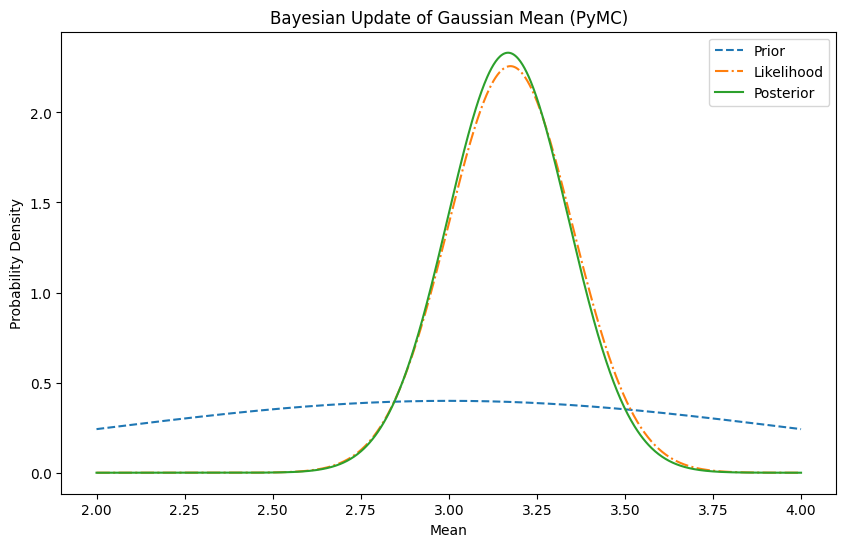

In [ ]:
# Plot prior, likelihood, and posterior
x = np.linspace(2, 4, 1000)  # Range of mu values to plot
prior = norm.pdf(x, mu_0, sigma_0)  # Prior distribution
likelihood = norm.pdf(x, np.mean(data), sigma / np.sqrt(len(data)))  # Likelihood
posterior = norm.pdf(x, mu_p, sigma_p)  # Posterior distribution

plt.figure(figsize=(10, 6))
plt.plot(x, prior, label="Prior", linestyle="--")
plt.plot(x, likelihood, label="Likelihood", linestyle="-.")
plt.plot(x, posterior, label="Posterior", linestyle="-")
plt.title("Bayesian Update of Gaussian Mean (PyMC)")
plt.xlabel("Mean")
plt.ylabel("Probability Density")
plt.legend()
plt.show()

Two metrics to assess convergence in MCMC are the **effective sample size** (ESS) and the **estimated potential scale reduction** (EPSRC) or **R-hat**.

We can use the [ArViz](https://python.arviz.org/en/stable/) package to compute both quantities.

In [ ]:
# Posterior summary (for more detailed diagnostics)
print(az.summary(trace, var_names=["mu"], hdi_prob=0.95))

     mean     sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
mu  3.168  0.171     2.843      3.499      0.004    0.002    1809.0    2806.0   

    r_hat  
mu    1.0  


**Question 2 (1 mark)**

The value of `r_hat` for the mean is equal to 1.0. Explain what `r_hat` computes and whether 1.0 is a good value. Explain why it is or why it is not a good value.

*Solution*

R-hat is an MCMC convergence diagnostic that compares variation between chains with variation within chains. A value close to 1 indicates that the chains are sampling consistently from the same posterior distribution. Therefore, the reported value of 1.0 is a good result and suggests convergence, as there is little evidence of disagreement between chains. However, R-hat alone does not guarantee convergence and should be considered alongside other diagnostics, such as effective sample size and trace plots.

## 2 Bayesian logistic regression with PyMC

In the module Topics in Machine Learning, we spend some time on a linear model for classification called **logistic regression**.

In a binary classification problem, let $\mathbf{X}=[\mathbf{x}_1 \cdots \mathbf{x}_N]^\top$ and and $\mathbf{y} =[y_1\cdots y_N]^{\top}$, where $\mathbf{X}$ is the design matrix and each element in $\mathbf{y}$, say $y_n$ indicates to which class the corresponding input vector, $\mathbf{x}_n$, belongs to.

Assumming IID observations, the likelihood for the dataset is given as
\begin{align*}
p(\mathbf{y}|\mathbf{w},\mathbf{X}) = \prod_{n=1}^Np(y_n|\mathbf{w},\mathbf{x}_n)
  =\prod_{n=1}^N\textrm{Ber}(y_n|\sigma(\mathbf{w}^{\top}\mathbf{x}_n)),
\end{align*}
where $\textrm{Ber}(y_n|\mu)$ refers to the Bernoulli distribution with parameter $\mu$, and $\sigma(a)$ is the sigmoid function defined as $\sigma(a)=\frac{1}{1+ \exp(-a)}$.

The maximum-likelihood estimator for $\mathbf{w}$ can be obtained by minimising the negative log-likelihood (or the cross-entropy function) given as

\begin{align*}
NLL(\mathbf{w}) & = - \log p(\mathbf{y}|\mathbf{w},\mathbf{X}) \\
& = - \sum_{n=1}^N\{y_n\log[\sigma(\mathbf{w}^{\top}\mathbf{x}_n)] + (1-y_n)\log[1 - \sigma(\mathbf{w}^{\top}\mathbf{x}_n)] \}.
\end{align*}

In *Bayesian logistic regression*, we put a prior over the weights $\mathbf{w}$. We then compute the posterior distribution
\begin{align*}
p(\mathbf{w}|\mathbf{X}, \mathbf{y}) \propto p(\mathbf{y}|\mathbf{w}, \mathbf{X})p(\mathbf{w}).
\end{align*}
For predicting the class of a text point, $\mathbf{x}_*$, we need to compute the predictive distribution,
\begin{align}
p(y_*|\mathbf{x}_*)=\int \sigma(\mathbf{w}^{\top}\mathbf{x}_*)p(\mathbf{w}|\mathbf{X}, \mathbf{y})d\mathbf{w}.
\end{align}

If we approximate the posterior distribution $p(\mathbf{w}|\mathbf{X}, \mathbf{y})$ with a Gaussian posterior distribution,
\begin{align*}
p(\mathbf{w}|\mathbf{X}, \mathbf{y}) ≈ q(\mathbf{w}|\mathbf{X}, \mathbf{y}) = \mathcal{N}(\mathbf{w}|𝛍_{\text{post}}, 𝚺_{\text{post}}),
\end{align*}
it can be shown the predictive distribution can also be approximated as
\begin{align*}
p(y_*=1|\mathbf{x}_*) = \sigma(\kappa (\sigma^2_a)\mu_a),
\end{align*}
where
\begin{align*}
\mu_a &= 𝛍_{\text{post}}^\top\mathbf{x}_*,\\
\sigma_a^2 &= \mathbf{x}^\top_*𝚺_{\text{post}}\mathbf{x}_*,\\
\kappa(\sigma^2) &= \frac{1}{(1+\pi \sigma^2/8)^{\frac{1}{2}}}
\end{align*}


### Bayesian logistic regression for the Iris dataset

To illustrate how Bayesian logistic regression works, we will use a very well known dataset, the [Iris dataset](https://archive.ics.uci.edu/dataset/53/iris). The dataset has three classes and four input features. We will only use two classes.

Let us load the dataset

In [ ]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

# fetch dataset
iris = fetch_ucirepo(id=53)

# data (as pandas dataframes)
X3 = iris.data.features
y3 = iris.data.targets
# Drop the last class and the last two columns
Xp = X3.drop(X3.index[100:150])
yp = y3.drop(y3.index[100:150])

We now have a reduced dataset that we will split into training and test

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
# We add a vector of ones to the input space in X
X = Xp.to_numpy()
# Add a column of ones to X
y = np.vstack((np.zeros((50, 1)), np.ones((50, 1))))
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=int(1e3))
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Question 3 (8 marks)**

Let us define the following prior distribution for $\mathbf{w}$, $p(\mathbf{w})= N(\mathbf{w}|\mathbf{0}_4, 0.001\times \mathbf{I}_4)$, where $\mathbf{0}_4 = [0, 0, 0, 0]^\top$ and $\mathbf{I}_4$ is the identity matrix of dimension four since there are four input features.

Using the training data `X_train` and `y_train`, compute an approximate posterior Gaussian distribution using PyMC for a Bayesian logistic regression model. Use 2000 samples for the sampler and report the mean and the covariance matrix for the approximate Gaussian using the last 1000 samples of one of the chains (**6 marks**)

*Solution*

In [ ]:
# Bayesian logistic regression with four weights and no extra intercept.
with pm.Model() as logistic_model:
    # The prior covariance is 0.001 * I, so sigma is sqrt(0.001).
    w = pm.Normal(
        "w", mu=0, sigma=np.sqrt(0.001), shape=X_train.shape[1]
    )

    # One linear score per observation; logit_p applies the logistic link.
    logits = pm.math.dot(X_train, w)
    likelihood = pm.Bernoulli(
        "y_obs", logit_p=logits, observed=y_train.ravel()
    )

    # Retain 2000 draws per chain after a separate warm-up period.
    trace_lr = pm.sample(
        draws=2000,
        tune=1000,
        chains=2,
        cores=2,
        random_seed=42,
        return_inferencedata=True,
    )

# Use only the last 1000 draws of the first chain, as required.
w_samples = (
    trace_lr.posterior["w"]
    .isel(chain=0, draw=slice(-1000, None))
    .transpose("draw", "w_dim_0")
    .values
)

# Estimate the mean and covariance of the Gaussian posterior approximation.
mu_post = w_samples.mean(axis=0)
Sigma_post = np.cov(w_samples, rowvar=False)

print("Sample shape:", w_samples.shape)
print("Posterior mean:\n", mu_post)
print("Posterior covariance:\n", Sigma_post)


Output()

Sample shape: (1000, 4)
Posterior mean:
 [ 0.01925132 -0.01934288  0.02840037  0.02767024]
Posterior covariance:
 [[ 1.00699679e-03 -8.53434922e-05  2.92218925e-05  3.21060589e-05]
 [-8.53434922e-05  1.07603440e-03  2.48988808e-05  4.67538764e-05]
 [ 2.92218925e-05  2.48988808e-05  1.00699086e-03  1.66338189e-05]
 [ 3.21060589e-05  4.67538764e-05  1.66338189e-05  1.04435300e-03]]


Compute the accuracy of the linear classifier over the test set using the approximated distribution $p(y_*=1|\mathbf{x}_*) = \sigma(\kappa (\sigma^2_a)\mu_a)$, as explained above (**2 marks**).

*Solution*

In [ ]:
# Write your code here

from scipy.special import expit


def predict_probability(X, mean, covariance):
    """Approximate class-1 probabilities using the Gaussian weight posterior."""
    mu_a = X @ mean
    # For each row x, compute x.T @ covariance @ x.
    var_a = np.sum((X @ covariance) * X, axis=1)
    kappa = 1 / np.sqrt(1 + np.pi * var_a / 8)
    return expit(kappa * mu_a)


prob_test = predict_probability(X_test, mu_post, Sigma_post)
y_pred = (prob_test >= 0.5).astype(int)

# Flatten the labels so each prediction is compared with one true label.
accuracy = np.mean(y_pred == y_test.ravel())
print(f"Test accuracy: {accuracy:.2%}")


Test accuracy: 100.00%
